# G×Age on overlapping SNPs, expressed in every generation: does it change the result?

**The question.** `04_results.ipynb` adds the child phenotype in the final generation only, as child effects at the same SNPs (β_child = r_g·β_adult + √(1 − r_g²)·β_U).

The alternative design (raised by the advisor) differs in two ways:
- **Overlapping SNPs.** The genetic correlation comes from an overlapping set of SNPs, and each age has its own SNPs.
- **Every generation.** The child trait is expressed in every generation, so that G×Age arises through the random passing of SNPs.

This notebook runs that design for one condition and compares it with the current design.

**Short answer: it does not change the result.** The check uses one condition, primary phenotypic AM at u = .5 (r_g = .5), with 30 populations in each design.
- **Child moments.** The child's trio moments agree between the designs (|z| ≤ .9).
- **The precise models agree to about .001.** "RDR on both a" gives .125 vs .126, and "different traits, latent parents" gives .132 vs .133.
- **The noisier models differ by up to 1.9 SE.**
  - Model 2: .111 vs .135. "RDR on the child's a": .152 vs .164.
  - Both are fit to the same datasets, so these two differences are not independent. The pooled fits give the same picture (1.7 and 1.5 SE).
  - A second set of 30 populations in the *current* design (the earlier paired run) gives Model 2 f̂ = .122, between the two: batches of 30 scatter this much even within one design.

This is what theory predicts (Section 1): child phenotypes never feed back into mating or transmission, and overlapping SNPs give the same expected covariances as the current construction.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

CUR, OVL = Path("output"), Path("output_overlap")
MECH, U, F_TRUE = "primary", .5, .15
CUR_REPS = range(151, 181)                     # the current design's populations of this cell (independent design)
truth = pd.read_csv(CUR / "truth" / "gxage_truth.csv")
exact = truth[(truth.mating == MECH) & (truth.f == F_TRUE) & (np.isclose(truth.u, U))].set_index("quantity").value

def fits(root):
    m2 = pd.read_csv(root / "sim_fits.csv").assign(model="M2")
    rd = pd.read_csv(root / "rdr_fits.csv")
    d = pd.concat([m2[["model", "mechanism", "rep", "pooled", "u", "parameter", "estimate"]],
                   rd[["model", "mechanism", "rep", "pooled", "u", "parameter", "estimate"]]], ignore_index=True)
    return d[(d.mechanism == MECH) & np.isclose(d.u, U) & ~d.pooled & (d.parameter == "f11")]
f_cur = fits(CUR); f_cur = f_cur[f_cur.rep.isin(CUR_REPS)]
f_ovl = fits(OVL)

INK, INK2, RULE = "#0b0b0b", "#52514e", "#dcdad5"
DCOL = {"current design": INK2, "overlapping SNPs": "#2a78d6"}   # neutral reference + reference palette slot 1
MODEL_LAB = {"M2": "Model 2 (no RDR)", "EstA": "RDR on the child's a", "FixA": "RDR on both a",
             "SameLat": "same trait, latent parents", "DiffLat": "different traits, latent parents"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": RULE,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": RULE,
                     "grid.linewidth": .6, "font.size": 10, "legend.frameon": False,
                     "savefig.bbox": "tight", "savefig.dpi": 150})
pd.set_option("display.width", 160, "display.max_columns", 30)
print(f"condition: {MECH} AM, u = {U} (r_g = {1 - U}), true f = {F_TRUE}; "
      f"current design {f_cur.rep.nunique()} populations, overlapping-SNP design {f_ovl.rep.nunique()} populations")

condition: primary AM, u = 0.5 (r_g = 0.5), true f = 0.15; current design 30 populations, overlapping-SNP design 30 populations


## 1. The two designs, and why they should agree

| | Current design (`01_simulate.py`) | Overlapping SNPs (`06_simulate_overlap.py`) |
|---|---|---|
| Adult trait | 1,000 SNPs: 400 in the PGS, 600 latent | the same |
| Child genetic value | r_g·G_adult + √(1 − r_g²)·G_U at the same 1,000 SNPs, with G_U orthogonal to the adult effects | a random (1 − u) share of the adult SNPs with the same effect, plus round(u·1,000) child-only SNPs; the adult's other SNPs do not affect the child |
| Child's base genetic variance | VG0 (the adult's) | VG0 (child-only SNPs scaled to make it exact) |
| Where the child trait is expressed | final generation only | every generation (GeneEvolve's trait 2) |
| Mating, vertical transmission | on the adult mating phenotype; F = f·(Yp + Ym) from adult phenotypes | the same |

Both designs give r_g = 1 − u. The overlapping design's realized r_g varies a little between populations, with which SNPs happen to be shared.

**Why the results should not change.**
1. **Child phenotypes are inert.** Spouses assort on adult phenotypes, and parents pass on F from their adult phenotypes. No generation's child phenotype feeds back into mating or transmission.
   - So expressing the child trait in every generation cannot change the final trios. It only produces phenotypes that nothing uses.
   - SNPs are passed on randomly every generation in both designs. The child effects only weight the inherited genotypes.
2. **Same expected covariances.** With a random (1 − u) share of SNPs shared, every quantity Model 2 sees scales by (1 − u), exactly as in the current design:
   - the child genetic value's covariance with the PGS haplotypes, with the latent score, with the parents and with F;
   - the child's genetic variance, VG0 + (1 − u)²·(AM-induced variance).
   - So both designs share the same expected trio covariance, `gxageSpec` in `conditions.R`. Only finite-locus noise differs.

**What would make G×Age matter beyond the final generation:** a feedback channel. For example, spouses assorting on a phenotype expressed at another age, or parents passing on F through a phenotype at a different age than the one measured. Neither design has one.

**The check.** One condition where the current design shows a clear G×Age effect: primary phenotypic AM at u = .5 (r_g = .5).
- **Overlapping-SNP design:** 30 new populations.
- **Current design:** its 30 populations of the same cell.
- **Models:** the same five, with the same RDR inputs (`03_fit_sim.R`, `05_fit_rdr.R --out output_overlap`).

## 2. Is the overlapping-SNP simulation what was intended?

The realized genetic correlation between adult and child expression:
- **Base population:** set by the SNP draw.
- **Final generation:** after 30 generations of AM, which inflate only the adult-trait (shared plus adult-only) variance. That raises the realized correlation a little above the base value, in both designs.

In [2]:
dg = pd.read_csv(OVL / "sim" / "diagnostics.csv")
dc = pd.read_csv(CUR / "sim" / "diagnostics.csv")
dc = dc[(dc.mechanism == MECH) & dc.rep.isin(CUR_REPS)]
summ = pd.DataFrame({
    "overlapping SNPs": {"populations": len(dg), "shared SNPs": dg.n_shared.mean(), "child-only SNPs": dg.n_child_only.mean(),
                         "child base genetic variance / VG0": (dg.VG_child_base / dg.VG0).mean(),
                         "r_g, base population (mean)": dg.rg_base.mean(), "r_g, base population (range)": f"{dg.rg_base.min():.3f}-{dg.rg_base.max():.3f}",
                         "r_g, final generation (mean)": dg.rg_final_generation.mean()},
    "current design": {"populations": len(dc), "shared SNPs": 1000, "child-only SNPs": 0,
                       "child base genetic variance / VG0": 1.0, "r_g, base population (mean)": 1 - U,
                       "r_g, base population (range)": "exactly 0.5",
                       "r_g, final generation (mean)": dc[f"rg_realized_u{round(100 * U):03d}"].mean()}})
summ.map(lambda v: round(v, 3) if isinstance(v, float) else v)

,overlapping SNPs,current design
populations,30,30
shared SNPs,500.0,1000
child-only SNPs,500.0,0
child base genetic variance / VG0,1.0,1.0
"r_g, base population (mean)",0.499,0.5
"r_g, base population (range)",0.433-0.556,exactly 0.5
"r_g, final generation (mean)",0.556,0.559


**The child's trio moments vs the exact G×Age covariance.** These are the four moments that involve the child's phenotype: var(Yo), θT = cov(Yo, T), θNT = cov(Yo, NT) per haplotype, and cov(Yo, Yp). Each is computed on all offspring of the final generation and compared with the exact value from `gxageSpec`, for both designs (z = (mean − exact)/SE).

The last column tests the difference between the two designs.

In [3]:
tr = pd.read_csv(OVL / "sim" / "trajectory.csv")
last = tr.loc[tr.groupby("rep").gen.idxmax()]
ovl = pd.DataFrame({"VY_o": last.VY_off_o, "thetaT": last.thetaT_o, "thetaNT": last.thetaNT_o, "Yo_Yp": last.Yo_Yp_o})
mom = pd.read_csv(CUR / "sim" / "moments.csv")
cur = mom[(mom.mechanism == MECH) & np.isclose(mom.u, U) & mom.rep.isin(CUR_REPS)].pivot(index="rep", columns="quantity", values="value")
rows = []
for q, lab in [("VY_o", "var(Yo)"), ("thetaT", "θT"), ("thetaNT", "θNT"), ("Yo_Yp", "cov(Yo, Yp)")]:
    c, o = cur[q], ovl[q]
    sc, so = c.std() / np.sqrt(len(c)), o.std() / np.sqrt(len(o))
    rows.append({"moment": lab, "exact": exact[q], "current mean": c.mean(), "z current": (c.mean() - exact[q]) / sc,
                 "overlap mean": o.mean(), "z overlap": (o.mean() - exact[q]) / so,
                 "z (overlap − current)": (o.mean() - c.mean()) / np.hypot(sc, so)})
pd.DataFrame(rows).set_index("moment").round(4)

,exact,current mean,z current,overlap mean,z overlap,z (overlap − current)
moment,,,,,,
var(Yo),0.8080,0.8055,-0.9356,0.8019,-2.1753,-0.9117
θT,0.1816,0.1793,-1.8586,0.1804,-0.4740,0.3700
θNT,0.0945,0.0932,-0.9111,0.0922,-1.5473,-0.4954
"cov(Yo, Yp)",0.3931,0.3871,-2.2885,0.3878,-1.6895,0.1659


## 3. The bias of f in both designs

For each model: the mean of the population estimates (true f = .15), its Monte Carlo SE and the relative bias, in both designs. The last column tests the difference between the designs: z = (overlap − current)/√(SE₁² + SE₂²).

In [4]:
def summarize(d, lab):
    g = d.groupby("model").estimate
    return pd.DataFrame({f"{lab}: mean f̂": g.mean(), f"{lab}: MC SE": g.std() / np.sqrt(g.size()),
                         f"{lab}: bias (%)": 100 * (g.mean() - F_TRUE) / F_TRUE, f"{lab}: n": g.size()})
cmpf = summarize(f_cur, "current").join(summarize(f_ovl, "overlap"))
cmpf["difference"] = cmpf["overlap: mean f̂"] - cmpf["current: mean f̂"]
cmpf["z"] = cmpf.difference / np.hypot(cmpf["current: MC SE"], cmpf["overlap: MC SE"])
cmpf = cmpf.reindex(list(MODEL_LAB)).rename(index=MODEL_LAB)
cmpf.round({c: (1 if "%" in c else 0 if c.endswith(": n") else 2 if c == "z" else 4) for c in cmpf.columns})

,current: mean f̂,current: MC SE,current: bias (%),current: n,overlap: mean f̂,overlap: MC SE,overlap: bias (%),overlap: n,difference,z
model,,,,,,,,,,
Model 2 (no RDR),0.1107,0.0088,-26.2,30,0.1347,0.0087,-10.2,30,0.0240,1.93
RDR on the child's a,0.1518,0.0049,1.2,30,0.1642,0.0049,9.5,30,0.0124,1.78
RDR on both a,0.1254,0.0011,-16.4,30,0.1263,0.0010,-15.8,30,0.0009,0.59
"same trait, latent parents",-0.1201,0.0122,-180.1,30,-0.1364,0.0136,-190.9,30,-0.0163,-0.89
"different traits, latent parents",0.1316,0.0008,-12.3,30,0.1330,0.0008,-11.3,30,0.0014,1.22


**Two checks on the differences.**
- **Pooled fits.** Each model is also fit once to the 30 populations of each design pooled (about 121,000 trios). This gives a second, model-based comparison.
- **Scatter within one design.** The earlier paired run (archived in `output/paired/`) used the *current* design on a different set of 30 populations (reps 1–30). Its Model 2 estimate shows how much two batches of 30 differ within the same design.

In [5]:
def pooledFits(root):
    m2 = pd.read_csv(root / "sim_fits.csv").assign(model="M2")
    rd = pd.read_csv(root / "rdr_fits.csv")
    d = pd.concat([m2[["model", "mechanism", "pooled", "u", "parameter", "estimate", "SE"]],
                   rd[["model", "mechanism", "pooled", "u", "parameter", "estimate", "SE"]]])
    return d[(d.mechanism == MECH) & np.isclose(d.u, U) & d.pooled & (d.parameter == "f11")].set_index("model")[["estimate", "SE"]]
pl = pooledFits(CUR).join(pooledFits(OVL), lsuffix=" current", rsuffix=" overlap")
pl["z"] = (pl["estimate overlap"] - pl["estimate current"]) / np.hypot(pl["SE current"], pl["SE overlap"])
display(pl.reindex(list(MODEL_LAB)).rename(index=MODEL_LAB).round(4))
pr = pd.read_csv(CUR / "paired" / "sim_fits.csv")
pr = pr[(pr.parameter == "f11") & ~pr.pooled & (pr.mechanism == MECH) & np.isclose(pr.u, U)]
sets = [("current design, reps 151-180 (main run)", f_cur[f_cur.model == "M2"].estimate),
        (f"current design, reps {int(pr.rep.min())}-{int(pr.rep.max())} (paired run)", pr.estimate),
        ("overlapping SNPs, reps 1-30", f_ovl[f_ovl.model == "M2"].estimate)]
print("Model 2, mean f̂ in three independent sets of 30 populations:")
for lab, e in sets:
    print(f"  {lab:<42} {e.mean():.4f}  (MC SE {e.std() / np.sqrt(len(e)):.4f})")

,estimate current,SE current,estimate overlap,SE overlap,z
model,,,,,
Model 2 (no RDR),0.1098,0.0105,0.1344,0.0105,1.6528
RDR on the child's a,0.1517,0.0059,0.1642,0.0059,1.5002
RDR on both a,0.1255,0.0007,0.1264,0.0007,0.9180
"same trait, latent parents",-0.1115,0.0087,-0.1242,0.0095,-0.9904
"different traits, latent parents",0.1317,0.0011,0.1334,0.0010,1.1884


Model 2, mean f̂ in three independent sets of 30 populations:
  current design, reps 151-180 (main run)    0.1107  (MC SE 0.0088)
  current design, reps 1-30 (paired run)     0.1218  (MC SE 0.0111)
  overlapping SNPs, reps 1-30                0.1347  (MC SE 0.0087)


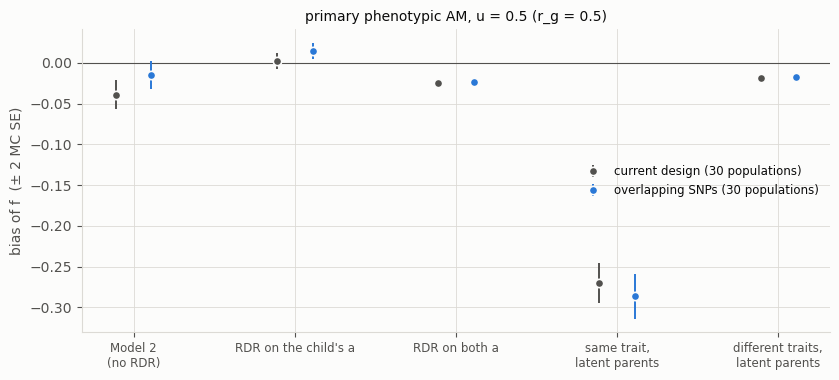

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.axhline(0, color=INK2, lw=.8)
x = np.arange(len(MODEL_LAB))
for k, (lab, d) in enumerate([("current design", f_cur), ("overlapping SNPs", f_ovl)]):
    g = d.groupby("model").estimate
    m = (g.mean() - F_TRUE).reindex(list(MODEL_LAB)); se = (g.std() / np.sqrt(g.size())).reindex(list(MODEL_LAB))
    ax.errorbar(x + (k - .5) * .22, m, yerr=2 * se, fmt="o", ms=6, color=DCOL[lab], mec="#fcfcfb", mew=1.2,
                elinewidth=1.4, capsize=0, label=f"{lab} ({d.rep.nunique()} populations)")
ax.set_xticks(x); ax.set_xticklabels([MODEL_LAB[m].replace(", ", ",\n").replace(" (", "\n(") for m in MODEL_LAB], fontsize=8.5)
ax.set_ylabel("bias of f  (± 2 MC SE)")
ax.set_title(f"primary phenotypic AM, u = {U} (r_g = {1 - U})", fontsize=10, color=INK)
ax.legend(loc="center right", fontsize=8.5)
fig.tight_layout(); fig.savefig(OVL / "overlap_vs_current_f.png"); plt.show()

## 4. Conclusion

1. **The simulated data have the same structure.** With overlapping SNPs and the child trait expressed in every generation, the child's trio moments agree with the current design's (|z| ≤ .9).
2. **The estimates of f agree within sampling noise.**
   - The precise models ("RDR on both a", and "different traits, latent parents") agree to about .001.
   - Model 2 and "RDR on the child's a" differ by 1.8–1.9 SE, within the batch-to-batch scatter of the current design itself (Model 2: .111 and .122 in two sets of 30).
   - The realized r_g of each overlap population (.43–.56) does not explain Model 2's estimates (correlation −.18).
3. **Why.**
   - No generation's child phenotype feeds back into mating or vertical transmission, so expressing it every generation changes nothing.
   - Random overlapping SNP sets scale every covariance by (1 − u), as the current construction does.
4. **Limits of this check.**
   - **Scope.** One condition, 30 populations per design.
   - **Model 2.** A design difference smaller than about ±.025 in f (2 SE of the difference) cannot be excluded.
   - **Feedback.** For G×Age to matter beyond the final generation, the model would need a feedback channel, for example assortment or transmission through a phenotype at a different age than the one measured.